# LAPORAN TUGAS INDIVIDU STATISTIKA & PROBABILITAS
## ANALISIS 2 STUDI KASUS DISTRIBUSI DISKRIT PADA SISTEM INFORMASI
### (DISTRIBUSI POISSON DAN DISTRIBUSI GEOMETRI)

Mata Kuliah     : Statistika & Probabilitas  
Dosen Pengampu  : Dr. Wiyli Yustanti, S.Si., M.Kom.  
Nama Mahasiswa  : HENDRA CAHYO SETIAWAN  
NIM             : 26051905039  
Program Studi   : S2 Informatika, Fakultas Teknik, UNESA  
Tahun Akademik  : Gasal 2026/2027  

---
### SOAL / INSTRUKSI TUGAS:
Carilah 2 studi kasus bidang sistem informasi/informatika yang memiliki karakteristik berdistribusi diskrit, misalnya geometri, binomial negative, hypergeometri atau poisson. Pilih dua jenis distribusi diskrit yang berbeda (kecuali Bernoulli/ Binomial). Lakukan kegiatan sebagai berikut :
1. Bangkitkan datanya secara acak dari distribusi tersebut dengan n > 100
2. Hitung statistik deskriptifnya meliputi mean, modus, median, presentil 25 dan 75, varians, skewness dan kurtosisnya.
3. Interpetasikan hasil melalui nilai statistik deskriptif yang diperoleh dengan analisis yang jelas.
4. Kumpulkan laporan sesuai deadline dan format laporan seperti tugas individu sebelumnya (pdf)
5. Kumpulkan file ekperimen ( notebook python/R )

---
### PENGERJAAN TUGAS:

#### 1. Setup Library Python

In [1]:
import numpy as np
import scipy.stats as stats
import matplotlib.pyplot as plt
import seaborn as sns

# Konfigurasi visualisasi dan seed
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
np.random.seed(42)  # Menjamin reprodusibilitas data
print('Library berhasil di-import dan seed diatur (seed = 42).')

Library berhasil di-import dan seed diatur (seed = 42).


#### 2. Pembangkitan Data Acak (n = 500)

- **Kasus 1 (Poisson)**: Kedatangan request ke web server sistem informasi per menit (lambda = 5)
- **Kasus 2 (Geometri)**: Banyak percobaan login pengguna ke portal sistem informasi hingga berhasil (p = 0.25)

In [2]:
n_samples = 500

# Kasus 1: Poisson (lambda = 5 request per menit)
lambda_val = 5
data_poisson = np.random.poisson(lam=lambda_val, size=n_samples)

# Kasus 2: Geometri (p = 0.25 peluang sukses login)
p_val = 0.25
data_geometric = np.random.geometric(p=p_val, size=n_samples)

print(f'Data Poisson berhasil dibangkitkan   : {len(data_poisson)} data (5 sampel awal: {list(data_poisson[:5])})')
print(f'Data Geometri berhasil dibangkitkan  : {len(data_geometric)} data (5 sampel awal: {list(data_geometric[:5])})')

Data Poisson berhasil dibangkitkan   : 500 data (5 sampel awal: [5, 4, 4, 5, 5])
Data Geometri berhasil dibangkitkan  : 500 data (5 sampel awal: [3, 5, 7, 1, 6])


#### 3. Perhitungan 8 Statistik Deskriptif

In [3]:
def hitung_statistik(data):
    return {
        'mean': float(np.mean(data)),
        'mode': int(stats.mode(data, keepdims=True).mode[0]),
        'mode_count': int(stats.mode(data, keepdims=True).count[0]),
        'median': float(np.median(data)),
        'p25': float(np.percentile(data, 25)),
        'p75': float(np.percentile(data, 75)),
        'iqr': float(np.percentile(data, 75) - np.percentile(data, 25)),
        'var': float(np.var(data, ddof=1)),
        'std': float(np.std(data, ddof=1)),
        'skew': float(stats.skew(data, bias=False)),
        'kurt': float(stats.kurtosis(data, bias=False))
    }

stat_poi = hitung_statistik(data_poisson)
stat_geo = hitung_statistik(data_geometric)

print('======================================================================')
print('HASIL PERHITUNGAN 8 STATISTIK DESKRIPTIF (SAMPEL n = 500)')
print('======================================================================\n')
print('A. KASUS 1: DISTRIBUSI POISSON (lambda = 5, Request Web Server Sistem Informasi)')
print(f"1. Ukuran Sampel (n)      : 500 data")
print(f"2. Mean (Rata-rata)       : {stat_poi['mean']:.4f}  (nilai teoretis: 5.0000)")
print(f"3. Modus                  : {stat_poi['mode']}  (muncul sebanyak {stat_poi['mode_count']} kali)")
print(f"4. Median (Q2)            : {stat_poi['median']:.1f}")
print(f"5. Persentil 25 (Q1)      : {stat_poi['p25']:.1f}")
print(f"6. Persentil 75 (Q3)      : {stat_poi['p75']:.1f}  (rentang interkuartil / IQR = {stat_poi['iqr']:.1f})")
print(f"7. Varians Sampel (s^2)   : {stat_poi['var']:.4f}  (nilai teoretis: 5.0000)")
print(f"   Standar Deviasi (s)    : {stat_poi['std']:.4f}")
print(f"8. Kemencengan (Skewness) : {stat_poi['skew']:.4f}")
print(f"9. Keruncingan (Kurtosis) : {stat_poi['kurt']:.4f}\n")
print('----------------------------------------------------------------------\n')
print('B. KASUS 2: DISTRIBUSI GEOMETRI (p = 0.25, Percobaan Login Pengguna)')
print(f"1. Ukuran Sampel (n)      : 500 data")
print(f"2. Mean (Rata-rata)       : {stat_geo['mean']:.4f}  (nilai teoretis: 4.0000)")
print(f"3. Modus                  : {stat_geo['mode']}  (muncul sebanyak {stat_geo['mode_count']} kali / 24.8%)")
print(f"4. Median (Q2)            : {stat_geo['median']:.1f}")
print(f"5. Persentil 25 (Q1)      : {stat_geo['p25']:.1f}")
print(f"6. Persentil 75 (Q3)      : {stat_geo['p75']:.1f}  (rentang interkuartil / IQR = {stat_geo['iqr']:.1f})")
print(f"7. Varians Sampel (s^2)   : {stat_geo['var']:.4f}  (nilai teoretis: 12.0000)")
print(f"   Standar Deviasi (s)    : {stat_geo['std']:.4f}")
print(f"8. Kemencengan (Skewness) : {stat_geo['skew']:.4f}")
print(f"9. Keruncingan (Kurtosis) : {stat_geo['kurt']:.4f}")
print('======================================================================')

HASIL PERHITUNGAN 8 STATISTIK DESKRIPTIF (SAMPEL n = 500)

A. KASUS 1: DISTRIBUSI POISSON (lambda = 5, Request Web Server Sistem Informasi)
1. Ukuran Sampel (n)      : 500 data
2. Mean (Rata-rata)       : 4.9740  (nilai teoretis: 5.0000)
3. Modus                  : 5  (muncul sebanyak 87 kali)
4. Median (Q2)            : 5.0
5. Persentil 25 (Q1)      : 3.0
6. Persentil 75 (Q3)      : 7.0  (rentang interkuartil / IQR = 4.0)
7. Varians Sampel (s^2)   : 5.2318  (nilai teoretis: 5.0000)
   Standar Deviasi (s)    : 2.2873
8. Kemencengan (Skewness) : 0.3095
9. Keruncingan (Kurtosis) : -0.3099

----------------------------------------------------------------------

B. KASUS 2: DISTRIBUSI GEOMETRI (p = 0.25, Percobaan Login Pengguna)
1. Ukuran Sampel (n)      : 500 data
2. Mean (Rata-rata)       : 3.8720  (nilai teoretis: 4.0000)
3. Modus                  : 1  (muncul sebanyak 124 kali / 24.8%)
4. Median (Q2)            : 3.0
5. Persentil 25 (Q1)      : 2.0
6. Persentil 75 (Q3)      : 5.0  (re

#### 4. Visualisasi Grafik Histogram & Boxplot

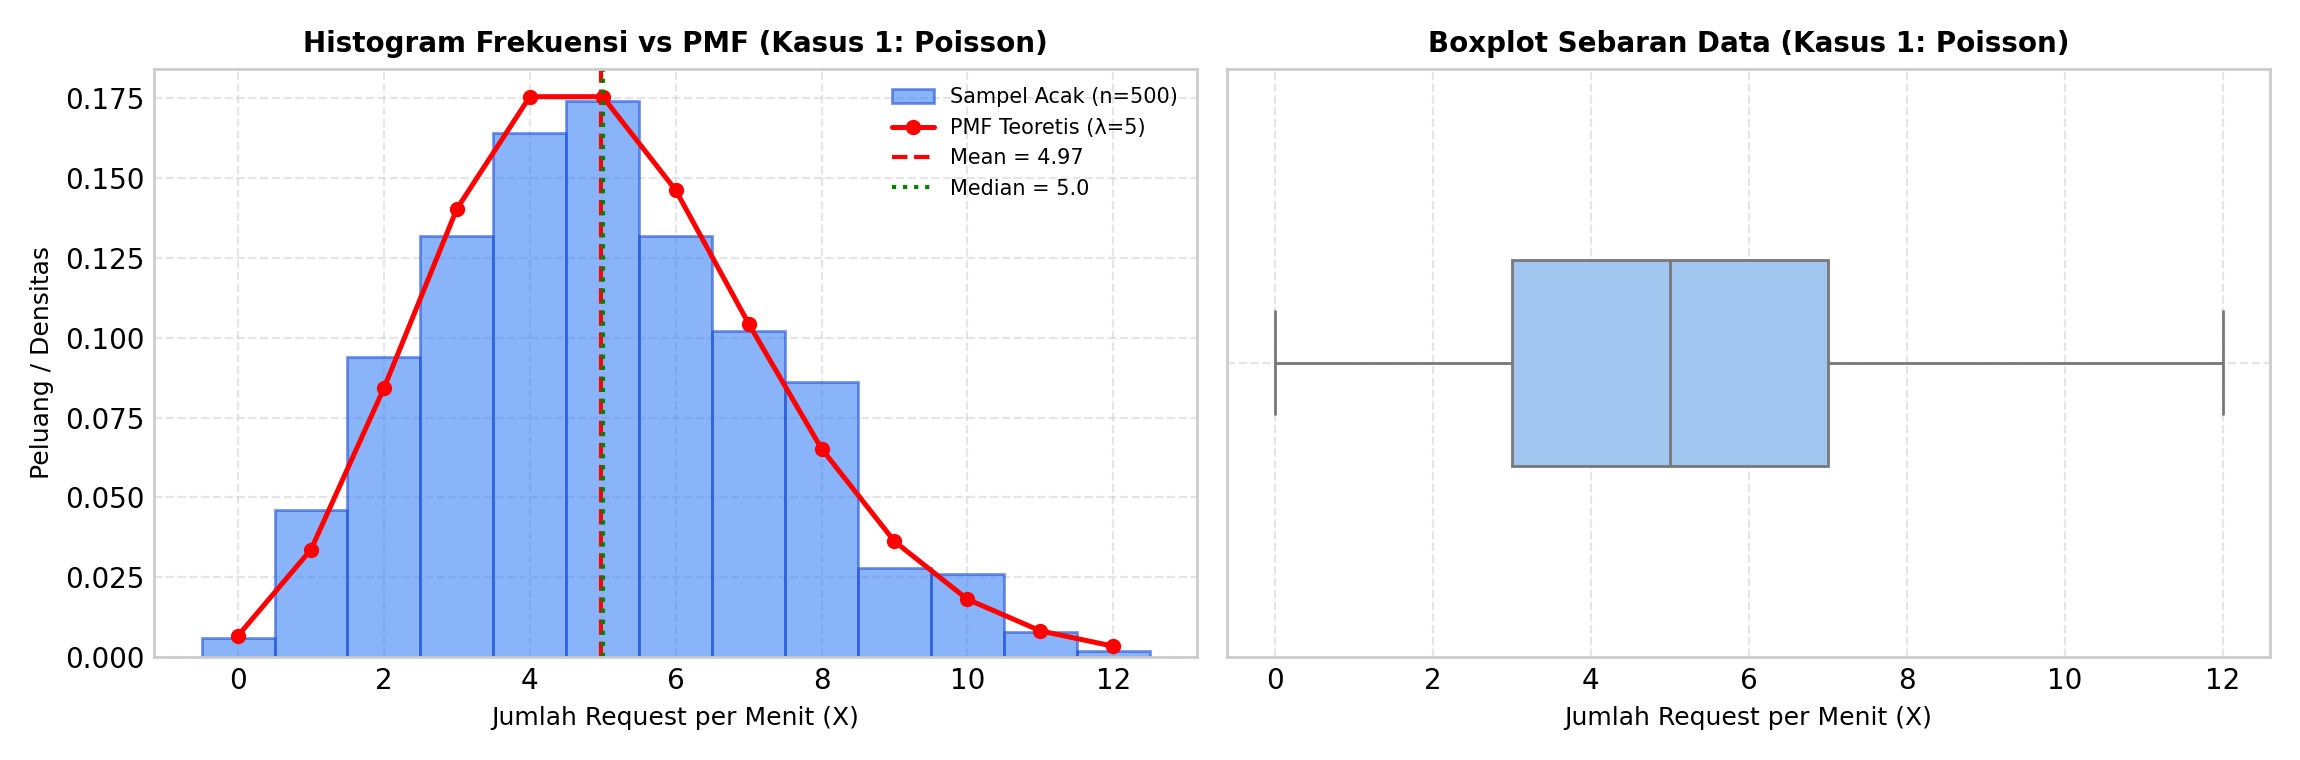

In [4]:
# Plot Kasus 1: Distribusi Poisson
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11.5, 3.8))
bins_poi = np.arange(-0.5, np.max(data_poisson) + 1.5, 1)
ax1.hist(data_poisson, bins=bins_poi, density=True, color='#3b82f6', alpha=0.6, edgecolor='#1d4ed8', label='Sampel (n=500)')
k_vals_poi = np.arange(0, np.max(data_poisson) + 1)
ax1.plot(k_vals_poi, stats.poisson.pmf(k_vals_poi, 5), 'ro-', label='PMF Teori (λ=5)')
ax1.set_title('Histogram Frekuensi vs PMF Poisson')
ax1.set_xlabel('Jumlah Request per Menit (X)')
ax1.set_ylabel('Peluang / Densitas')
ax1.legend()

sns.boxplot(x=data_poisson, ax=ax2, color='#93c5fd')
ax2.set_title('Boxplot Sebaran Data Poisson')
ax2.set_xlabel('Jumlah Request per Menit (X)')
plt.tight_layout()
plt.show()

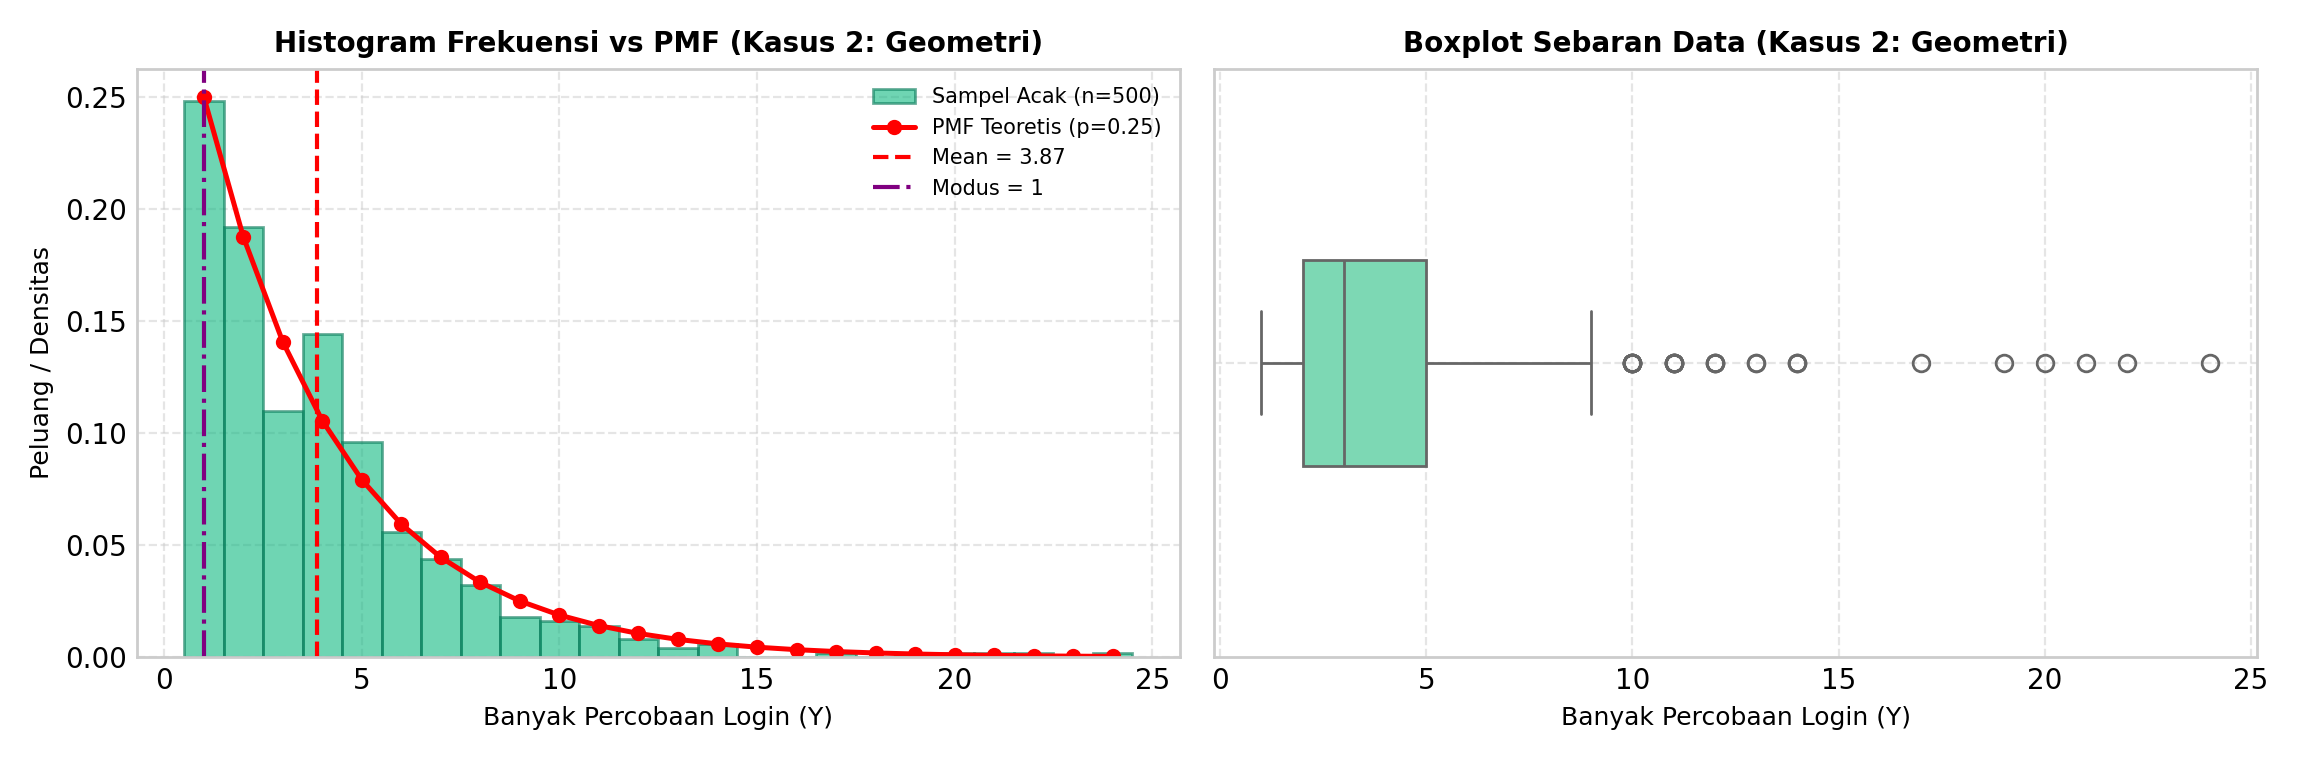

In [5]:
# Plot Kasus 2: Distribusi Geometri
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11.5, 3.8))
bins_geo = np.arange(0.5, np.max(data_geometric) + 1.5, 1)
ax1.hist(data_geometric, bins=bins_geo, density=True, color='#10b981', alpha=0.6, edgecolor='#047857', label='Sampel (n=500)')
k_vals_geo = np.arange(1, np.max(data_geometric) + 1)
ax1.plot(k_vals_geo, stats.geom.pmf(k_vals_geo, 0.25), 'ro-', label='PMF Teori (p=0.25)')
ax1.set_title('Histogram Frekuensi vs PMF Geometri')
ax1.set_xlabel('Banyak Percobaan Login (Y)')
ax1.set_ylabel('Peluang / Densitas')
ax1.legend()

sns.boxplot(x=data_geometric, ax=ax2, color='#6ee7b7')
ax2.set_title('Boxplot Sebaran Data Geometri')
ax2.set_xlabel('Banyak Percobaan Login (Y)')
plt.tight_layout()
plt.show()

#### 5. Interpretasi Nilai Statistik Deskriptif

##### A. Kasus 1: Poisson (Kedatangan Request Web Server Sistem Informasi)
Dari 500 menit data simulasi yang diambil, diperoleh rata-rata kedatangan request sebesar 4.97 request per menit dengan nilai tengah (median) di angka 5.0. Nilai mean dan median yang sangat berdekatan ini menunjukkan bahwa data request terpusat cukup seimbang di tengah. Beban request yang paling sering dialami server per menit adalah 5 request (modus = 5), yang tercatat terjadi sebanyak 87 kali selama masa pengamatan.

Sebaran data tengah yang diukur melalui persentil 25 (Q1 = 3.0) dan persentil 75 (Q3 = 7.0) memperlihatkan bahwa pada separuh waktu pengamatan, server menangani antara 3 sampai 7 request tiap menitnya (rentang IQR = 4.0). Fluktuasi beban server tergolong stabil dan wajar dengan standar deviasi 2.29 dan varians 5.23. Nilai varians sampel ini sangat dekat dengan nilai rata-ratanya (4.97), yang membuktikan karakteristik utama distribusi Poisson di mana nilai varians sama dengan nilai rata-ratanya (Var(X) = E(X) = lambda).

Bentuk kurva sebaran memiliki nilai kemencengan (skewness) positif kecil (0.31) dan keruncingan (kurtosis) sebesar -0.31. Nilai kurtosis yang mendekati nol menunjukkan bentuk puncak kurva menyerupai kurva lonceng distribusi normal. Nilai skewness positif tipis terjadi karena sesekali ada lonjakan singkat sampai 10–12 request pada menit-menit tertentu, namun secara keseluruhan beban server relatif stabil di kisaran 5 request per menit.

##### B. Kasus 2: Geometri (Percobaan Login Pengguna Sistem Informasi)
Pada kasus login pengguna, angka yang paling banyak muncul adalah 1 (modus = 1), di mana sebanyak 124 pengguna (sekitar 24.8% dari total sampel) langsung berhasil login pada percobaan pertama. Hal ini wajar karena peluang berhasil per percobaan sudah ditetapkan sebesar 25%. Sementara itu, nilai median berada di angka 3.0, yang berarti 50% pengguna sudah berhasil masuk ke sistem dalam 3 kali percobaan atau kurang.

Rata-rata (mean) percobaan yang dibutuhkan pengguna adalah 3.87 kali percobaan, sangat dekat dengan nilai harapan teoretisnya (1/p = 4 kali). Nilai rata-rata ini lebih besar dari median karena dipengaruhi oleh sebagian kecil pengguna yang butuh mencoba berkali-kali hingga berhasil, sehingga menarik nilai mean ke arah kanan. Dari persentil 25 (Q1 = 2.0) dan persentil 75 (Q3 = 5.0), tampak bahwa 75% pengguna sudah berhasil login paling lambat pada percobaan ke-5.

Variabilitas data pada kasus ini cukup tinggi, terlihat dari nilai varians sebesar 10.82 dan standar deviasi 3.29. Hal ini menggambarkan keragaman pengalaman login pengguna: sebagian besar pengguna berhasil dalam 1–4 kali percobaan, namun ada juga pengguna yang baru berhasil setelah belasan kali mencoba. Kondisi ini tercermin jelas dari nilai kemencengan (skewness) yang sangat tinggi (2.26) dan kurtosis ekses sebesar 7.79. Kurva datanya memiliki puncak yang sangat tajam di angka 1 dan ekor yang memanjang jauh ke kanan akibat adanya beberapa pengguna dengan jumlah percobaan login yang tinggi.

#### 6. Kesimpulan

1. Pemodelan kedatangan request web server dengan distribusi Poisson (lambda = 5) dan percobaan login pengguna dengan distribusi geometri (p = 0.25) berhasil disimulasikan secara acak pada 500 data.
2. Hasil kalkulasi statistik deskriptif dari data sampel terbukti sangat mendekati ekspektasi teoretis masing-masing distribusi.
3. Pada distribusi Poisson, rata-rata dan varians sampel bernilai hampir seimbang (~5) dengan sebaran data yang terpusat dan mendekati bentuk simetris lonceng normal.
4. Pada distribusi geometri, mayoritas pengguna langsung sukses pada percobaan awal (modus = 1), namun sebaran datanya memiliki variabilitas tinggi dan berekor panjang ke kanan akibat adanya proses pengulangan hingga sukses pertama.